In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.model_selection import GroupShuffleSplit
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

In [2]:
EDA_DIR = Path("eda_data")

df_games_clean = pd.read_parquet(
    EDA_DIR / "games_clean.parquet"
)

df_steam_eda = pd.read_parquet(
    EDA_DIR / "steam_reviews_summary.parquet"
)

df_steam_map_clean = pd.read_parquet(
    EDA_DIR / "steam_map_clean.parquet"
)

print("--- DATASETS CARGADOS ---")

print("IGDB:", df_games_clean.shape)
print("Steam:", df_steam_eda.shape)
print("Mapping:", df_steam_map_clean.shape)

--- DATASETS CARGADOS ---
IGDB: (236126, 21)
Steam: (27795, 7)
Mapping: (181352, 7)


In [3]:
df_mapping = (
    df_steam_map_clean[["game", "uid"]]
    .rename(columns={
        "game": "igdb_id",
        "uid": "appid"
    })
    .drop_duplicates()
    .copy()
)

df_mapping["igdb_id"] = pd.to_numeric(
    df_mapping["igdb_id"],
    errors="coerce"
)

df_mapping["appid"] = pd.to_numeric(
    df_mapping["appid"],
    errors="coerce"
)

df_mapping = (
    df_mapping
    .dropna(subset=["igdb_id", "appid"])
    .astype({
        "igdb_id": "int64",
        "appid": "int64"
    })
)

print("Correspondencias:", len(df_mapping))
print("AppIDs únicos:", df_mapping["appid"].nunique())

Correspondencias: 181306
AppIDs únicos: 181306


In [4]:
df_igdb_metadata = (
    df_games_clean[
        [
            "id",
            "name",
            "release_year",
            "genres_clean",
            "is_indie",
            "platforms_names",
            "game_modes_names"
        ]
    ]
    .rename(columns={
        "id": "igdb_id",
        "name": "game_name"
    })
)

df_steam_igdb = (
    df_steam_eda
    .merge(
        df_mapping,
        on="appid",
        how="inner",
        validate="one_to_one"
    )
    .merge(
        df_igdb_metadata,
        on="igdb_id",
        how="inner",
        validate="many_to_one"
    )
)

print("--- STEAM + IGDB ---")

print("Filas:", len(df_steam_igdb))
print("AppIDs:", df_steam_igdb["appid"].nunique())
print("Juegos IGDB:", df_steam_igdb["igdb_id"].nunique())

display(df_steam_igdb.head())

--- STEAM + IGDB ---
Filas: 21350
AppIDs: 21350
Juegos IGDB: 21346


,appid,extracted_at,total_positive,total_negative,total_reviews,review_count_downloaded,positive_pct,igdb_id,game_name,release_year,genres_clean,is_indie,platforms_names,game_modes_names
0,1000000,2026-11-09T21:27:55.255411+00:00,35.0,8.0,43.0,43,81.395349,117247,Ascenxion,2021,[Adventure],True,[PC (Microsoft Windows)],[Single player]
1,1000040,2026-11-09T04:19:10.176038+00:00,0.0,1.0,1.0,1,0.000000,116112,Xìbāo Zhànzhēng,2019,[Simulator],True,[PC (Microsoft Windows)],[Single player]
2,1000360,2026-11-09T22:26:32.895578+00:00,7605.0,1010.0,8615.0,8614,88.276262,139472,Hellish Quart,2021,[Fighting],True,[PC (Microsoft Windows)],"[Single player, Multiplayer]"
3,1000380,2026-11-07T00:34:36.065530+00:00,320.0,86.0,406.0,405,78.817734,113522,Rogue Reaper,2019,[Adventure],True,[PC (Microsoft Windows)],[Single player]
4,1000410,2026-11-22T00:34:06.947307+00:00,2151.0,850.0,3001.0,3000,71.676108,115873,Wrath: Aeon of Ruin,2024,"[Shooter, Adventure]",False,"[PlayStation 4, Linux, PC (Microsoft Windows),...",[Single player]


In [5]:
ml_columns = [
    "appid",
    "igdb_id",
    "game_name",
    "release_year",
    "is_indie",
    "genres_clean",
    "platforms_names",
    "game_modes_names",
    "total_reviews"
]

display(
    df_steam_igdb[ml_columns].head()
)

print("\n--- VALORES NULOS ---")

display(
    df_steam_igdb[ml_columns]
    .isna()
    .sum()
)

,appid,igdb_id,game_name,release_year,is_indie,genres_clean,platforms_names,game_modes_names,total_reviews
0,1000000,117247,Ascenxion,2021,True,[Adventure],[PC (Microsoft Windows)],[Single player],43.0
1,1000040,116112,Xìbāo Zhànzhēng,2019,True,[Simulator],[PC (Microsoft Windows)],[Single player],1.0
2,1000360,139472,Hellish Quart,2021,True,[Fighting],[PC (Microsoft Windows)],"[Single player, Multiplayer]",8615.0
3,1000380,113522,Rogue Reaper,2019,True,[Adventure],[PC (Microsoft Windows)],[Single player],406.0
4,1000410,115873,Wrath: Aeon of Ruin,2024,False,"[Shooter, Adventure]","[PlayStation 4, Linux, PC (Microsoft Windows),...",[Single player],3001.0



--- VALORES NULOS ---


appid                 0
igdb_id               0
game_name             0
release_year          0
is_indie              0
genres_clean          0
platforms_names       0
game_modes_names      0
total_reviews       661
dtype: int64

In [6]:
df_ml = df_steam_igdb.loc[
    df_steam_igdb["total_reviews"].notna()
    & df_steam_igdb["total_reviews"].ge(0)
].copy()

print("--- DATASET ML ---")

print("Registros:", len(df_ml))
print("AppIDs únicos:", df_ml["appid"].nunique())
print("Juegos IGDB únicos:", df_ml["igdb_id"].nunique())

print("\n--- VARIABLE OBJETIVO ---")

display(
    df_ml["total_reviews"].describe(
        percentiles=[0.25, 0.50, 0.75, 0.90, 0.95, 0.99]
    )
)

--- DATASET ML ---
Registros: 20689
AppIDs únicos: 20689
Juegos IGDB únicos: 20685

--- VARIABLE OBJETIVO ---


count    2.068900e+04
mean     1.009535e+03
std      1.525349e+04
min      0.000000e+00
25%      6.000000e+00
50%      2.400000e+01
75%      1.080000e+02
90%      5.762000e+02
95%      1.751200e+03
99%      1.464596e+04
max      1.414080e+06
Name: total_reviews, dtype: float64

In [7]:
feature_columns = [
    "genres_clean",
    "platforms_names",
    "game_modes_names"
]

for col in feature_columns:

    empty_count = df_ml[col].apply(
        lambda x: len(x) == 0
    ).sum()

    print(
        f"{col}: {empty_count:,} juegos sin información "
        f"({empty_count / len(df_ml) * 100:.2f}%)"
    )

genres_clean: 3,108 juegos sin información (15.02%)
platforms_names: 0 juegos sin información (0.00%)
game_modes_names: 191 juegos sin información (0.92%)


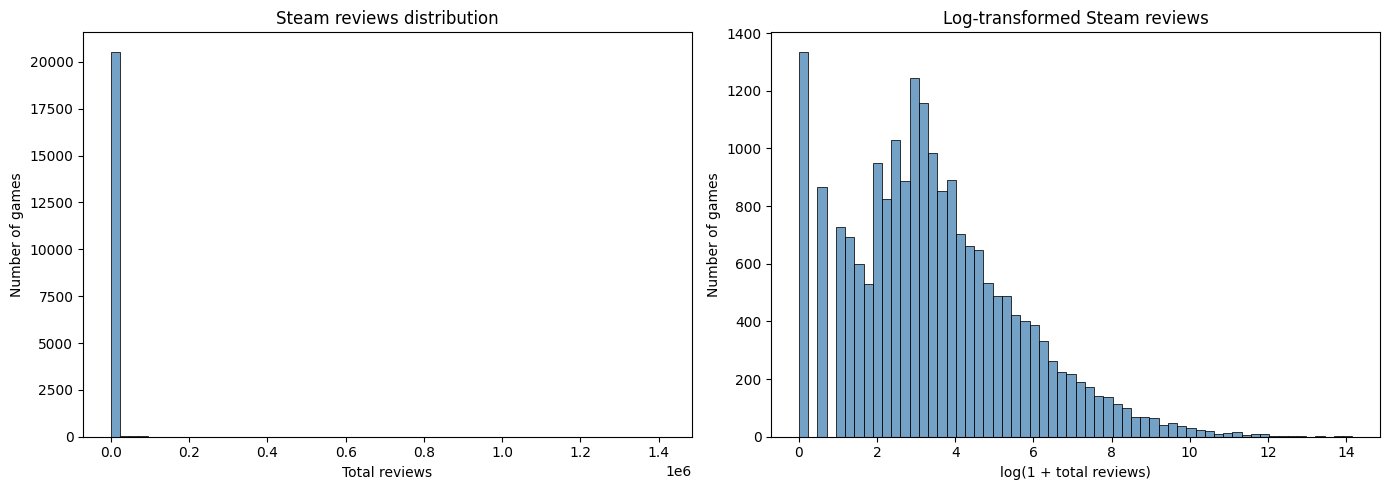

In [8]:
df_ml["log_reviews"] = np.log1p(
    df_ml["total_reviews"]
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(
    data=df_ml,
    x="total_reviews",
    bins=60,
    color="steelblue",
    ax=axes[0]
)

axes[0].set_title("Steam reviews distribution")
axes[0].set_xlabel("Total reviews")
axes[0].set_ylabel("Number of games")

sns.histplot(
    data=df_ml,
    x="log_reviews",
    bins=60,
    color="steelblue",
    ax=axes[1]
)

axes[1].set_title("Log-transformed Steam reviews")
axes[1].set_xlabel("log(1 + total reviews)")
axes[1].set_ylabel("Number of games")

plt.tight_layout()
plt.show()

In [9]:
from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df_ml,
        groups=df_ml["igdb_id"]
    )
)

df_train = df_ml.iloc[train_idx].copy()
df_test = df_ml.iloc[test_idx].copy()

print("Train:", len(df_train))
print("Test:", len(df_test))

Train: 16552
Test: 4137


In [10]:
def normalize_list(value):

    if isinstance(value, (list, tuple, np.ndarray)):
        return [
            str(item)
            for item in value
            if pd.notna(item)
        ]

    return []

In [11]:
# seleccionamos los 12 géneros y plataformas más frecuentes
feature_groups = {
    "genres_clean": ("genre", 12),
    "platforms_names": ("platform", 12),
    "game_modes_names": ("mode", None)
}

selected_labels = {}

for col, (prefix, top_n) in feature_groups.items():

    counts = (
        df_train[col]
        .apply(normalize_list)
        .explode()
        .dropna()
        .value_counts()
    )

    if top_n is not None:
        counts = counts.head(top_n)

    selected_labels[col] = counts.index.tolist()

    print(f"\n--- {prefix.upper()} ---")
    print(selected_labels[col])


--- GENRE ---
['Adventure', 'Simulator', 'Strategy', 'Role-playing (RPG)', 'Puzzle', 'Shooter', 'Arcade', 'Platform', 'Sport', 'Visual Novel', 'Racing', 'Point-and-click']

--- PLATFORM ---
['PC (Microsoft Windows)', 'Mac', 'Linux', 'Nintendo Switch', 'PlayStation 4', 'Xbox One', 'PlayStation 5', 'iOS', 'Android', 'Xbox Series X|S', 'SteamVR', 'Xbox 360']

--- MODE ---
['Single player', 'Multiplayer', 'Co-operative', 'Massively Multiplayer Online (MMO)', 'Split screen', 'Battle Royale']


In [12]:
def build_features(df):

    X = pd.DataFrame(index=df.index)

    X["release_year"] = df["release_year"].astype(float)
    X["is_indie"] = df["is_indie"].astype(int)

    for col, (prefix, _) in feature_groups.items():

        values = df[col].apply(normalize_list)

        # Indicador de metadatos ausentes
        X[f"{prefix}_unknown"] = (
            values.apply(len) == 0
        ).astype(int)

        # Variables binarias
        for label in selected_labels[col]:

            X[f"{prefix}_{label}"] = (
                values.apply(
                    lambda items: int(label in items)
                )
            )

    return X


X_train = build_features(df_train)
X_test = build_features(df_test)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

display(X_train.head())

X_train: (16552, 35)
X_test: (4137, 35)


,release_year,is_indie,genre_unknown,genre_Adventure,genre_Simulator,genre_Strategy,genre_Role-playing (RPG),genre_Puzzle,genre_Shooter,genre_Arcade,...,platform_Xbox Series X|S,platform_SteamVR,platform_Xbox 360,mode_unknown,mode_Single player,mode_Multiplayer,mode_Co-operative,mode_Massively Multiplayer Online (MMO),mode_Split screen,mode_Battle Royale
0,2021.0,1,0,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
2,2021.0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,1,1,0,0,0,0
4,2024.0,0,0,1,0,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
5,2021.0,1,0,1,0,0,0,1,0,0,...,1,0,0,0,1,0,0,0,0,0
6,2022.0,1,0,1,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0


In [13]:
y_train = np.log1p(
    df_train["total_reviews"].astype(float)
)

y_test = np.log1p(
    df_test["total_reviews"].astype(float)
)

print("Variable objetivo preparada")

print("Train:", y_train.shape)
print("Test:", y_test.shape)

Variable objetivo preparada
Train: (16552,)
Test: (4137,)


In [14]:
print("--- VALIDACIÓN FEATURES ---")

print("Variables predictoras:", X_train.shape[1])

print("Nulos en train:", X_train.isna().sum().sum())
print("Nulos en test:", X_test.isna().sum().sum())

print("Mismas columnas:", X_train.columns.equals(X_test.columns))

print(
    "Juegos IGDB compartidos entre train y test:",
    len(
        set(df_train["igdb_id"])
        & set(df_test["igdb_id"])
    )
)

--- VALIDACIÓN FEATURES ---
Variables predictoras: 35
Nulos en train: 0
Nulos en test: 0
Mismas columnas: True
Juegos IGDB compartidos entre train y test: 0


Antes de la regresión lineal, construiremos un modelo de referencia.

Utilizaremos DummyRegressor, que siempre predice la media de log_reviews del conjunto de entrenamiento, independientemente de las características del videojuego.

Nos servirá para comprobar si la regresión lineal realmente aprende algo útil.

In [15]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression

# Modelo baseline
baseline = DummyRegressor(strategy="mean")

baseline.fit(X_train, y_train)

y_pred_baseline = baseline.predict(X_test)

In [16]:
# Modelo de regresión lineal
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

# Predicciones sobre test
y_pred_linear = linear_model.predict(X_test)

print("Modelo entrenado correctamente")
print("Variables utilizadas:", X_train.shape[1])

Modelo entrenado correctamente
Variables utilizadas: 35


In [17]:
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

def evaluate_model(name, y_true, y_pred):

    return {
        "model": name,
        "MAE_log": mean_absolute_error(y_true, y_pred),
        "RMSE_log": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2_log": r2_score(y_true, y_pred)
    }


results = [
    evaluate_model(
        "Baseline",
        y_test,
        y_pred_baseline
    ),
    evaluate_model(
        "Linear Regression",
        y_test,
        y_pred_linear
    )
]

df_model_results = pd.DataFrame(results)

display(df_model_results.round(4))

,model,MAE_log,RMSE_log,R2_log
0,Baseline,1.6795,2.1477,-0.0004
1,Linear Regression,1.4867,1.9144,0.2051


Esto significa que las variables de IGDB —año, Indie, géneros, plataformas y modos— contienen información útil para predecir el volumen de reseñas.

Sin embargo, cerca del 79,5 % de la variabilidad en la escala transformada sigue sin estar explicada por el modelo.

In [18]:
# Recuperar número de reseñas
y_test_original = np.expm1(y_test)

y_pred_baseline_original = np.maximum(
    0,
    np.expm1(y_pred_baseline)
)

y_pred_linear_original = np.maximum(
    0,
    np.expm1(y_pred_linear)
)

df_results_original = pd.DataFrame([
    {
        "model": "Baseline",
        "MAE_reviews": mean_absolute_error(
            y_test_original,
            y_pred_baseline_original
        ),
        "RMSE_reviews": np.sqrt(
            mean_squared_error(
                y_test_original,
                y_pred_baseline_original
            )
        )
    },
    {
        "model": "Linear Regression",
        "MAE_reviews": mean_absolute_error(
            y_test_original,
            y_pred_linear_original
        ),
        "RMSE_reviews": np.sqrt(
            mean_squared_error(
                y_test_original,
                y_pred_linear_original
            )
        )
    }
])

display(df_results_original.round(2))

,model,MAE_reviews,RMSE_reviews
0,Baseline,1146.64,18199.17
1,Linear Regression,1141.38,18168.93


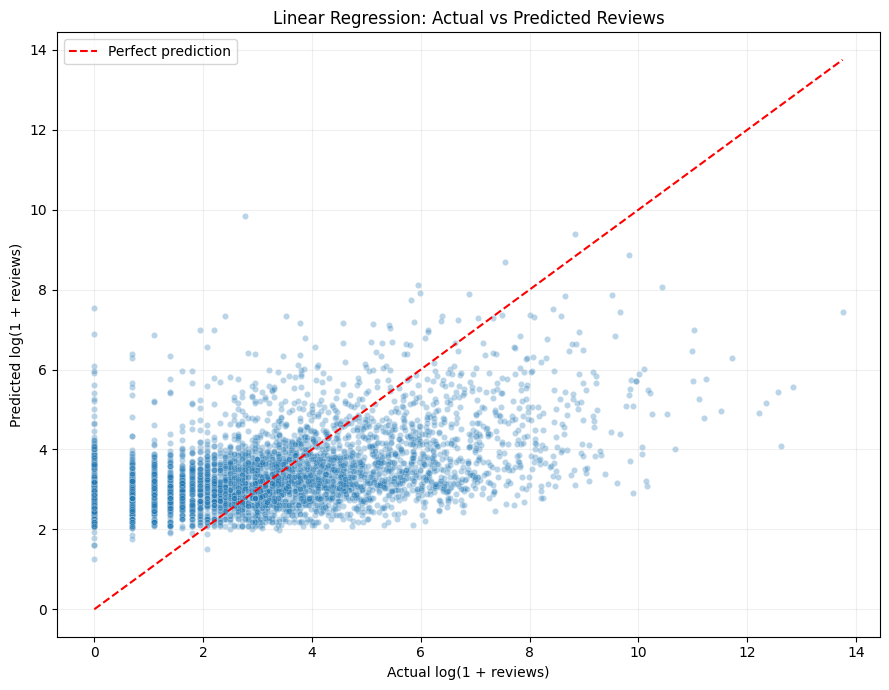

In [19]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred_linear,
    alpha=0.3,
    s=20
)

min_value = min(y_test.min(), y_pred_linear.min())
max_value = max(y_test.max(), y_pred_linear.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.title("Linear Regression: Actual vs Predicted Reviews")
plt.xlabel("Actual log(1 + reviews)")
plt.ylabel("Predicted log(1 + reviews)")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [20]:
df_coefficients = pd.DataFrame({
    "feature": X_train.columns,
    "coefficient": linear_model.coef_
})

df_coefficients = df_coefficients.sort_values(
    "coefficient",
    ascending=False
)

display(df_coefficients.round(4))

,feature,coefficient
27,platform_Xbox 360,2.2568
16,platform_PC (Microsoft Windows),1.5065
25,platform_Xbox Series X|S,1.1234
26,platform_SteamVR,1.0124
14,genre_Point-and-click,0.8389
32,mode_Massively Multiplayer Online (MMO),0.7721
20,platform_PlayStation 4,0.7493
8,genre_Shooter,0.6396
4,genre_Simulator,0.5453
12,genre_Visual Novel,0.5365


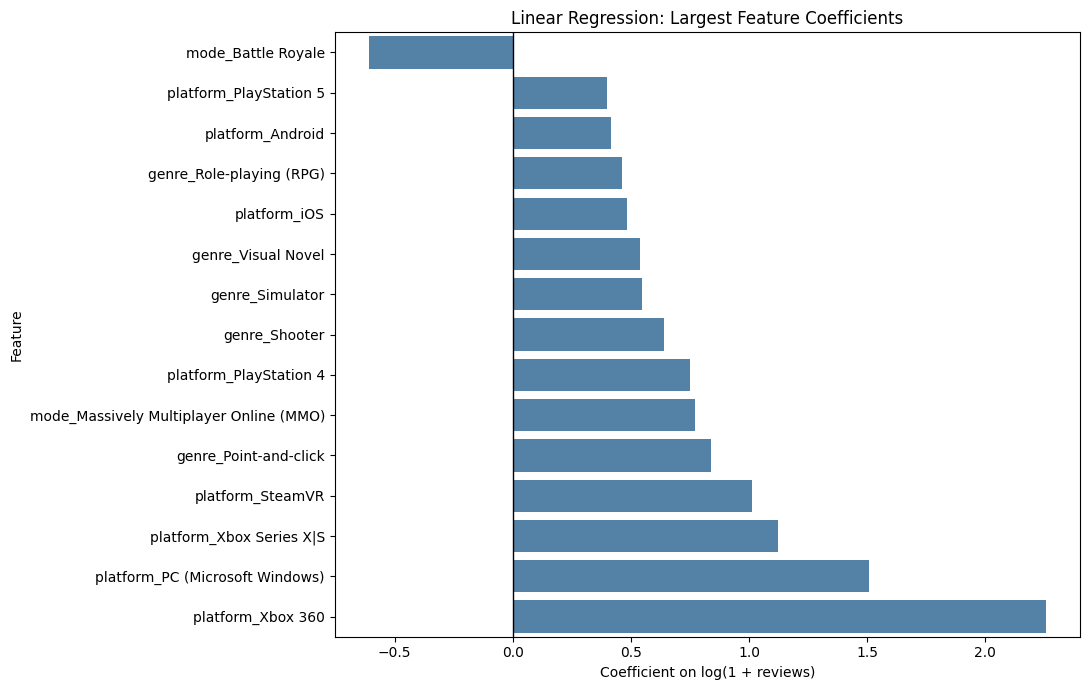

In [21]:
# Excluimos release_year, ya que es una variable numérica y los coeficientes no son directamente comparables con los de variables categóricas binarias

df_coefficients_binary = df_coefficients.loc[
    ~df_coefficients["feature"].isin(["release_year"])
].copy()

df_coefficients_binary["abs_coefficient"] = (
    df_coefficients_binary["coefficient"].abs()
)

df_top_coefficients = (
    df_coefficients_binary
    .nlargest(15, "abs_coefficient")
    .sort_values("coefficient")
)

plt.figure(figsize=(11, 7))

sns.barplot(
    data=df_top_coefficients,
    x="coefficient",
    y="feature",
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Linear Regression: Largest Feature Coefficients")
plt.xlabel("Coefficient on log(1 + reviews)")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Hay algo que me gustaría revisar antes de sacar conclusiones sobre la importancia de las variables: los coeficientes de una regresión lineal no son necesariamente una medida fiable de importancia predictiva.

Esto ocurre especialmente cuando existen:

- Variables correlacionadas, como Multiplayer y Co-operative.
- Plataformas que suelen aparecer juntas.
- Categorías poco frecuentes.
- Variables medidas en escalas diferentes.

Por eso, antes de Random Forest, propongo utilizar Permutation Importance.

Esta técnica evalúa cuánto empeora el modelo cuando mezclamos aleatoriamente los valores de una característica en el conjunto de test.

Si alterar una variable reduce considerablemente el R², significa que el modelo depende de ella para realizar sus predicciones.

4. Calcular Permutation Importance

Usaremos nuestro modelo ya entrenado y el conjunto de test, sin volver a entrenar.

In [22]:
from sklearn.inspection import permutation_importance

perm_result = permutation_importance(
    linear_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

df_importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm_result.importances_mean,
    "importance_std": perm_result.importances_std
})

df_importance = df_importance.sort_values(
    "importance_mean",
    ascending=False
)

display(df_importance.round(4))

,feature,importance_mean,importance_std
0,release_year,0.0646,0.0058
4,genre_Simulator,0.0232,0.0036
16,platform_PC (Microsoft Windows),0.0205,0.0020
25,platform_Xbox Series X|S,0.0187,0.0026
20,platform_PlayStation 4,0.0156,0.0018
6,genre_Role-playing (RPG),0.0124,0.0021
17,platform_Mac,0.0118,0.0022
12,genre_Visual Novel,0.0107,0.0011
8,genre_Shooter,0.0100,0.0028
14,genre_Point-and-click,0.0092,0.0010


El año de lanzamiento es la variable más importante

release_year tiene una importancia de 0,0646, muy superior a las demás.

Nuestro modelo obtiene un R² de 0,2051. Al mezclar aleatoriamente los años de lanzamiento, el R² disminuiría, en promedio, aproximadamente hasta 0,1405.

Esto sugiere que el año contiene bastante información predictiva.

Una posible explicación es que los videojuegos antiguos han tenido más tiempo para acumular reseñas, aunque también pueden influir diferencias entre generaciones, catálogo y cobertura de Steam.

Los géneros también aportan información

Los géneros con mayor importancia son:

Género	Importancia

Simulator	0,0232

RPG	0,0124

Visual Novel	0,0107

Shooter	0,0100

Point-and-click	0,0092

Es interesante que Simulator sea el género más importante para las predicciones, mientras que Adventure, el género más frecuente, apenas tiene importancia (0,0006).

Ser frecuente no implica ser predictivo.

Las plataformas tienen bastante peso

Windows, Xbox Series X|S, PlayStation 4 y Mac aparecen entre las variables más importantes.

Esto no significa que esas plataformas generen más reseñas por sí mismas. Recordemos que el modelo utiliza metadatos de IGDB para predecir reseñas acumuladas de Steam.

Las plataformas pueden estar actuando como indicadores indirectos de antigüedad, tipo de videojuego, disponibilidad o popularidad.

Multiplayer y Co-operative tienen una asociación positiva con el volumen predicho de reseñas, pero su contribución individual al rendimiento del modelo es relativamente pequeña.

Esto encaja con lo observado en el Top 15 de juegos más reseñados: Multiplayer y Co-operative estaban presentes en 12 de los 15 títulos.

Sin embargo, también encontramos Single player en 12 de los 15.

Por tanto, estos resultados no demuestran que los juegos multijugador sean necesariamente más populares; indican que esa característica aporta cierta información adicional al modelo.

Indie apenas contribuye a las predicciones

is_indie tiene una importancia de solo 0,0005.

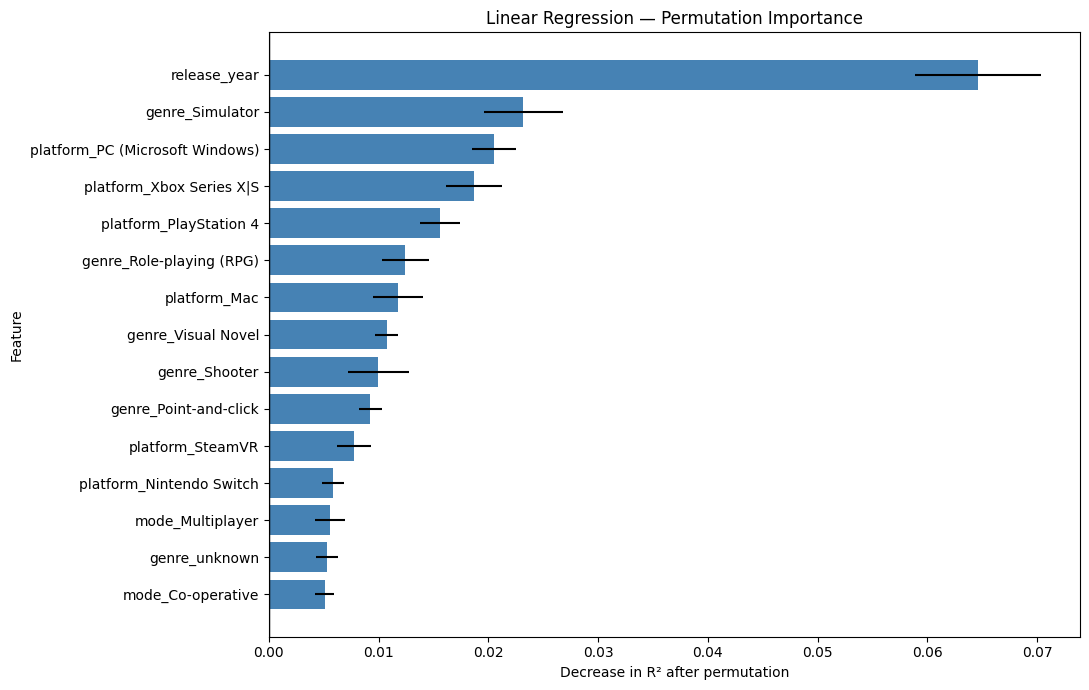

In [23]:
df_top_importance = (
    df_importance.head(15)
    .sort_values("importance_mean")
)

plt.figure(figsize=(11, 7))

plt.barh(
    df_top_importance["feature"],
    df_top_importance["importance_mean"],
    xerr=df_top_importance["importance_std"],
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Linear Regression — Permutation Importance")
plt.xlabel("Decrease in R² after permutation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Game Metadata Offers Limited Predictive Power for Steam Review Volume

A linear regression model using release year, genres, platforms, game modes and Indie classification explains 20.5% of the variance in log-transformed Steam review counts.

Release year is the most influential feature, suggesting that game age and historical context are important predictors of accumulated review activity.

#####################################################

# Random Forest

In [24]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

y_pred_rf = rf_model.predict(X_test)

print("Random Forest entrenado correctamente")

Random Forest entrenado correctamente


In [25]:
results = [
    evaluate_model(
        "Baseline",
        y_test,
        y_pred_baseline
    ),
    evaluate_model(
        "Linear Regression",
        y_test,
        y_pred_linear
    ),
    evaluate_model(
        "Random Forest",
        y_test,
        y_pred_rf
    )
]

df_model_comparison = pd.DataFrame(results)

display(
    df_model_comparison.round(4)
)

,model,MAE_log,RMSE_log,R2_log
0,Baseline,1.6795,2.1477,-0.0004
1,Linear Regression,1.4867,1.9144,0.2051
2,Random Forest,1.4372,1.8549,0.2538


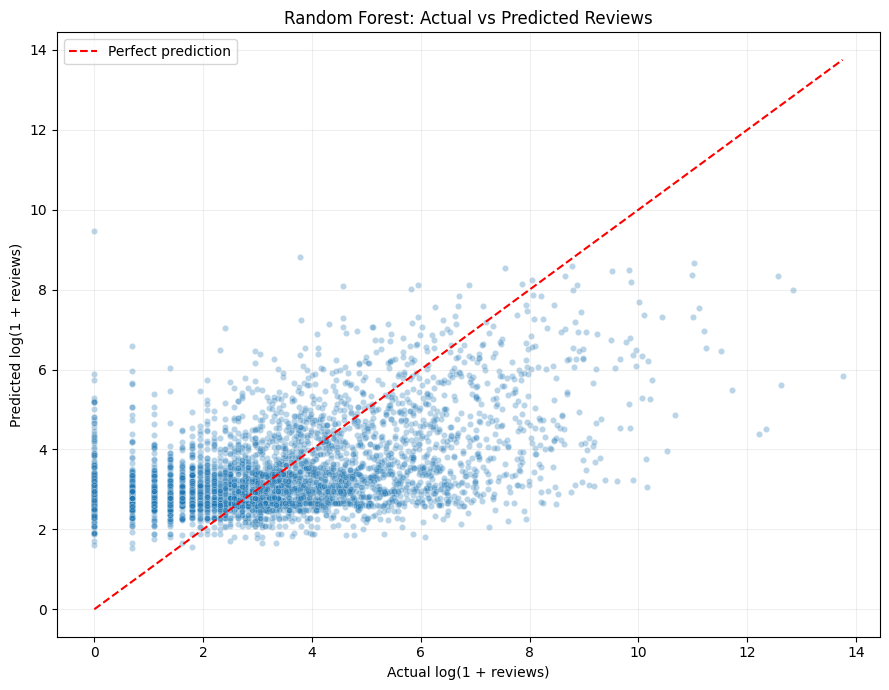

In [26]:
plt.figure(figsize=(9, 7))

sns.scatterplot(
    x=y_test,
    y=y_pred_rf,
    alpha=0.3,
    s=20
)

min_value = min(y_test.min(), y_pred_rf.min())
max_value = max(y_test.max(), y_pred_rf.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    color="red",
    linestyle="--",
    label="Perfect prediction"
)

plt.title("Random Forest: Actual vs Predicted Reviews")
plt.xlabel("Actual log(1 + reviews)")
plt.ylabel("Predicted log(1 + reviews)")

plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [27]:
rf_perm = permutation_importance(
    rf_model,
    X_test,
    y_test,
    scoring="r2",
    n_repeats=5,
    random_state=42,
    n_jobs=-1
)

df_rf_importance = (
    pd.DataFrame({
        "feature": X_test.columns,
        "importance_mean": rf_perm.importances_mean,
        "importance_std": rf_perm.importances_std
    })
    .sort_values("importance_mean", ascending=False)
)

display(df_rf_importance.round(4))

,feature,importance_mean,importance_std
0,release_year,0.1494,0.0103
25,platform_Xbox Series X|S,0.0399,0.0040
20,platform_PlayStation 4,0.0237,0.0023
4,genre_Simulator,0.0226,0.0037
19,platform_Nintendo Switch,0.0203,0.0022
2,genre_unknown,0.0169,0.0048
6,genre_Role-playing (RPG),0.0135,0.0009
22,platform_PlayStation 5,0.0127,0.0011
12,genre_Visual Novel,0.0126,0.0022
14,genre_Point-and-click,0.0101,0.0012


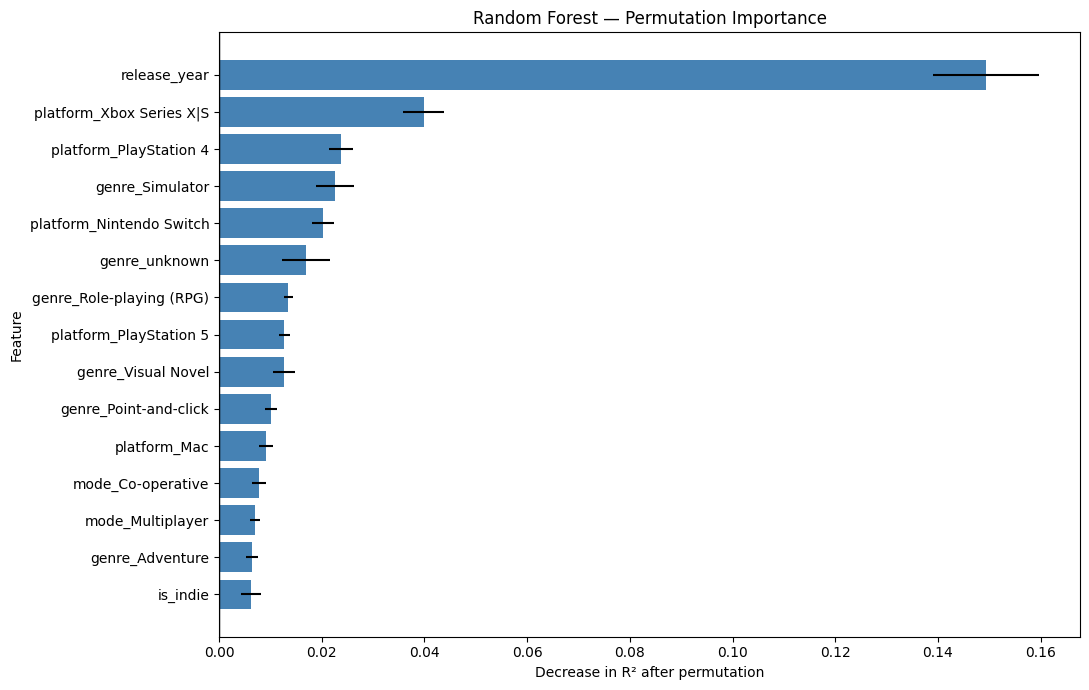

In [28]:
df_rf_top = (
    df_rf_importance.head(15)
    .sort_values("importance_mean")
)

plt.figure(figsize=(11, 7))

plt.barh(
    df_rf_top["feature"],
    df_rf_top["importance_mean"],
    xerr=df_rf_top["importance_std"],
    color="steelblue"
)

plt.axvline(0, color="black", linewidth=1)

plt.title("Random Forest — Permutation Importance")
plt.xlabel("Decrease in R² after permutation")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

Random Forest Improves Prediction, but Game Metadata Alone Is Insufficient

Random Forest outperformed linear regression in predicting log-transformed Steam review counts, increasing test R² from 0.205 to 0.254. However, both models struggled to predict exceptionally popular games, suggesting that release year, genres, platforms and game modes alone capture only part of the factors associated with accumulated review volume.

In [29]:
y_real = np.expm1(y_test)

predictions = {
    "Regresión lineal": np.expm1(y_pred_linear),
    "Random Forest": np.expm1(y_pred_rf)
}

results_original = []

for model, y_pred in predictions.items():
    results_original.append({
        "Modelo": model,
        "MAE_reseñas": mean_absolute_error(y_real, y_pred),
        "RMSE_reseñas": np.sqrt(
            mean_squared_error(y_real, y_pred)
        )
    })

display(pd.DataFrame(results_original).round(2))

,Modelo,MAE_reseñas,RMSE_reseñas
0,Regresión lineal,1141.38,18168.93
1,Random Forest,1125.00,18142.31


#####################################################

# ITAD ML

In [30]:
df_steam_eda["positive_pct"] = (
    df_steam_eda["total_positive"]
    / df_steam_eda["total_reviews"]
    * 100
)

# Los juegos sin reseñas no tienen valoración positiva calculable
df_steam_eda.loc[
    df_steam_eda["total_reviews"].le(0),
    "positive_pct"
] = np.nan

print("--- VALIDACIÓN STEAM ---")

print("AppIDs:", df_steam_eda["appid"].nunique())

print(
    "Con porcentaje positivo válido:",
    df_steam_eda["positive_pct"].between(0, 100).sum()
)

display(
    df_steam_eda[
        ["appid", "total_reviews", "total_positive",
         "total_negative", "positive_pct"]
    ].head()
)

--- VALIDACIÓN STEAM ---
AppIDs: 27795
Con porcentaje positivo válido: 20291


,appid,total_reviews,total_positive,total_negative,positive_pct
0,1000000,43.0,35.0,8.0,81.395349
1,1000040,1.0,0.0,1.0,0.000000
2,1000300,NaN,NaN,NaN,NaN
3,1000360,8615.0,7605.0,1010.0,88.276262
4,1000380,406.0,320.0,86.0,78.817734


In [31]:
EDA_DIR = Path("eda_data")

df_discount_ratings = pd.read_parquet(
    EDA_DIR / "itad_steam_igdb_ratings.parquet"
)

print("--- DATASET ITAD + STEAM + IGDB ---")

print("Dimensiones:", df_discount_ratings.shape)
print("AppIDs únicos:", df_discount_ratings["appid"].nunique())
print("Juegos IGDB únicos:", df_discount_ratings["igdb_id"].nunique())

display(df_discount_ratings.head())

--- DATASET ITAD + STEAM + IGDB ---
Dimensiones: (4375, 24)
AppIDs únicos: 4375
Juegos IGDB únicos: 4375


,appid,total_records,discount_records,max_discount_pct,mean_discount_pct,min_price_eur,max_regular_price_eur,first_price_date,last_price_date,discount_record_share_pct,...,is_indie,genres_clean,game_age,age_group,history_days,total_reviews,total_positive,total_negative,positive_pct,rating_category
0,2775180,64,32,51,25.328125,0.49,0.99,2024-01-25 13:37:45+01:00,2026-10-19 19:37:39+02:00,50.000000,...,True,[Point-and-click],2,2–3 years,998,266.0,228.0,38.0,85.714286,Mayormente positivas
1,2806230,26,13,40,11.346154,3.53,5.89,2024-04-18 06:00:31+02:00,2026-10-08 21:18:29+02:00,50.000000,...,False,[Simulator],2,2–3 years,903,153.0,145.0,8.0,94.771242,Muy positivas
2,2981650,46,23,50,21.086957,2.49,4.99,2024-07-23 16:48:05+02:00,2026-10-08 21:27:19+02:00,50.000000,...,True,"[Puzzle, Simulator, Adventure]",2,2–3 years,807,219.0,189.0,30.0,86.301370,Mayormente positivas
3,3029990,30,15,66,24.666667,2.34,6.89,2024-08-16 05:30:25+02:00,2026-10-08 21:27:30+02:00,50.000000,...,False,"[Role-playing (RPG), Simulator, Adventure]",2,2–3 years,783,382.0,265.0,117.0,69.371728,Mixtas
4,3076240,15,7,30,11.666667,5.45,7.79,2025-07-21 21:03:20+02:00,2026-11-02 19:38:15+01:00,46.666667,...,True,[Adventure],1,0–1 years,468,149.0,119.0,30.0,79.865772,Mayormente positivas


In [32]:
ITAD_DIR = Path("itad_etl")
ITAD_PARQUET_DIR = ITAD_DIR / "parquet_history"

df_itad_overview = pd.read_csv(
    ITAD_DIR / "itad_overview.csv"
)

df_itad_history_manifest = pd.read_csv(
    ITAD_DIR / "history_manifest.csv"
)

print("--- ITAD OVERVIEW ---")
print("Dimensiones:", df_itad_overview.shape)
print("Columnas:", df_itad_overview.columns.tolist())

print("\n--- ITAD HISTORY MANIFEST ---")
print("Dimensiones:", df_itad_history_manifest.shape)
print("Columnas:", df_itad_history_manifest.columns.tolist())

display(df_itad_overview.head(3))

--- ITAD OVERVIEW ---
Dimensiones: (105460, 16)
Columnas: ['itad_id', 'current_shop', 'current_price', 'current_currency', 'current_regular_price', 'current_discount_pct', 'current_price_timestamp', 'current_url', 'historical_low_shop', 'historical_low_price', 'historical_low_currency', 'historical_low_regular_price', 'historical_low_discount_pct', 'historical_low_timestamp', 'bundled', 'itad_url']

--- ITAD HISTORY MANIFEST ---
Dimensiones: (27952, 7)
Columnas: ['appid', 'itad_id', 'status', 'records_downloaded', 'elapsed_seconds', 'extracted_at', 'error']


,itad_id,current_shop,current_price,current_currency,current_regular_price,current_discount_pct,current_price_timestamp,current_url,historical_low_shop,historical_low_price,historical_low_currency,historical_low_regular_price,historical_low_discount_pct,historical_low_timestamp,bundled,itad_url
0,018d937e-f02b-70f6-bbc6-8bc3905a3d47,WinGameStore,1.08,EUR,3.62,70,2024-06-18T16:51:04+02:00,https://itad.link/018d9386-bf8c-72a2-8acf-8997...,WinGameStore,0.91,EUR,3.68,75.0,2024-05-30T17:55:52+02:00,4,https://isthereanydeal.com/game/id:018d937e-f0...
1,018d937e-f04f-73ae-9e54-a3ad5155c880,Steam,0.00,EUR,0.00,0,2024-02-11T06:16:26+01:00,https://itad.link/018d9386-d764-739b-9d45-9b02...,NaN,NaN,NaN,NaN,NaN,NaN,0,https://isthereanydeal.com/game/id:018d937e-f0...
2,018d937e-f52f-70dd-93e9-5b100e5a776b,Steam,2.39,EUR,2.39,0,2024-02-11T07:17:22+01:00,https://itad.link/018d9386-b5dd-71dc-b5ae-205a...,Steam,0.71,EUR,2.39,70.0,2019-08-10T19:40:58+02:00,0,https://isthereanydeal.com/game/id:018d937e-f5...


In [33]:
df_discount_ml = df_discount_ratings.dropna(
    subset=[
        "igdb_id",
        "game_age",
        "history_days",
        "total_records",
        "is_indie",
        "positive_pct",
        "max_discount_pct"
    ]
).copy()

df_discount_ml = df_discount_ml.loc[
    (df_discount_ml["history_days"] >= 0)
    & (df_discount_ml["total_records"] > 0)
].copy()

# Transformaciones logarítmicas
df_discount_ml["log_history_days"] = np.log1p(
    df_discount_ml["history_days"]
)

df_discount_ml["log_total_records"] = np.log1p(
    df_discount_ml["total_records"]
)

print("Videojuegos disponibles:", len(df_discount_ml))

display(
    df_discount_ml[
        [
            "game_age",
            "history_days",
            "log_history_days",
            "total_records",
            "log_total_records",
            "positive_pct",
            "max_discount_pct"
        ]
    ].head()
)

Videojuegos disponibles: 4375


,game_age,history_days,log_history_days,total_records,log_total_records,positive_pct,max_discount_pct
0,2,998,6.906755,64,4.174387,85.714286,51
1,2,903,6.806829,26,3.295837,94.771242,40
2,2,807,6.694562,46,3.850148,86.301370,50
3,2,783,6.664409,30,3.433987,69.371728,66
4,1,468,6.150603,15,2.772589,79.865772,30


In [34]:
splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(
        df_discount_ml,
        groups=df_discount_ml["igdb_id"]
    )
)

df_train_itad = df_discount_ml.iloc[train_idx].copy()
df_test_itad = df_discount_ml.iloc[test_idx].copy()

print("Train:", len(df_train_itad))
print("Test:", len(df_test_itad))

Train: 3500
Test: 875


In [35]:
def normalize_genres(value):
    if isinstance(value, (list, tuple, np.ndarray)):
        return [str(x) for x in value]
    return []

top_genres = (
    df_train_itad["genres_clean"]
    .apply(normalize_genres)
    .explode()
    .dropna()
    .value_counts()
    .head(10)
    .index
    .tolist()
)

def build_discount_features(df, include_rating=False):

    X = pd.DataFrame(index=df.index)

    X["game_age"] = df["game_age"].astype(float)
    X["log_history_days"] = df["log_history_days"]
    X["log_total_records"] = df["log_total_records"]
    X["is_indie"] = df["is_indie"].astype(int)

    genres = df["genres_clean"].apply(normalize_genres)

    X["genre_unknown"] = genres.apply(
        lambda x: int(len(x) == 0)
    )

    for genre in top_genres:
        X[f"genre_{genre}"] = genres.apply(
            lambda x: int(genre in x)
        )

    if include_rating:
        X["positive_pct"] = df["positive_pct"]

    return X

In [36]:
X_train_itad_A = build_discount_features(df_train_itad)
X_test_itad_A = build_discount_features(df_test_itad)

X_train_itad_B = build_discount_features(df_train_itad, include_rating=True)
X_test_itad_B = build_discount_features(df_test_itad, include_rating=True)

y_train_itad = df_train_itad["max_discount_pct"]
y_test_itad = df_test_itad["max_discount_pct"]

In [37]:
model_itad_A = LinearRegression()
model_itad_B = LinearRegression()

model_itad_A.fit(X_train_itad_A, y_train_itad)
model_itad_B.fit(X_train_itad_B, y_train_itad)

pred_itad_A = model_itad_A.predict(X_test_itad_A)
pred_itad_B = model_itad_B.predict(X_test_itad_B)

def evaluate_discount_model(name, y_true, y_pred):
    return {
        "model": name,
        "MAE_pp": mean_absolute_error(y_true, y_pred),
        "RMSE_pp": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

df_discount_model_results = pd.DataFrame([
    evaluate_discount_model("Modelo A - Sin valoraciones", y_test_itad, pred_itad_A),
    evaluate_discount_model("Modelo B - Con valoraciones", y_test_itad, pred_itad_B)
])

display(df_discount_model_results.round(4))

,model,MAE_pp,RMSE_pp,R2
0,Modelo A - Sin valoraciones,12.3731,15.7711,0.5719
1,Modelo B - Con valoraciones,11.6882,15.0189,0.6117


¿Los videojuegos con mejores valoraciones reciben descuentos menores?

Por ahora tenemos dos evidencias complementarias:
1. Análisis descriptivo: correlación de Spearman negativa (ρ = −0,2965), indicando que los videojuegos mejor valorados tienden a presentar descuentos máximos inferiores.
2. Machine Learning: añadir positive_pct mejora las tres métricas del modelo lineal en test, incluso al considerar otras características y la cobertura histórica.

In [38]:
df_itad_coefficients = pd.DataFrame({
    "feature": X_train_itad_B.columns,
    "coefficient": model_itad_B.coef_
}).sort_values(
    "coefficient"
)

display(df_itad_coefficients.round(4))

,feature,coefficient
13,genre_Visual Novel,-3.1429
7,genre_Role-playing (RPG),-2.6391
6,genre_Simulator,-0.7490
3,is_indie,-0.6217
15,positive_pct,-0.2970
8,genre_Strategy,-0.1545
0,game_age,0.5152
4,genre_unknown,1.6123
10,genre_Shooter,1.7749
5,genre_Adventure,1.8527


In [39]:
rating_coefficient = df_itad_coefficients.loc[
    df_itad_coefficients["feature"] == "positive_pct",
    "coefficient"
].iloc[0]

print("--- EFECTO ASOCIADO A LAS VALORACIONES ---")

print(
    f"Coeficiente positive_pct: {rating_coefficient:.4f}"
)

print(
    "Cambio estimado en el descuento máximo "
    "por +10 puntos porcentuales de valoración:",
    round(rating_coefficient * 10, 2),
    "puntos porcentuales"
)

--- EFECTO ASOCIADO A LAS VALORACIONES ---
Coeficiente positive_pct: -0.2970
Cambio estimado en el descuento máximo por +10 puntos porcentuales de valoración: -2.97 puntos porcentuales


In [40]:
itad_perm = permutation_importance(
    model_itad_B,
    X_test_itad_B,
    y_test_itad,
    scoring="r2",
    n_repeats=10,
    random_state=42,
    n_jobs=-1
)

df_itad_importance = pd.DataFrame({
    "feature": X_test_itad_B.columns,
    "importance_mean": itad_perm.importances_mean,
    "importance_std": itad_perm.importances_std
}).sort_values(
    "importance_mean",
    ascending=False
)

display(df_itad_importance.round(4))

,feature,importance_mean,importance_std
2,log_total_records,0.3871,0.0174
1,log_history_days,0.1109,0.0088
15,positive_pct,0.0710,0.0081
0,game_age,0.0252,0.0059
11,genre_Platform,0.0056,0.0026
5,genre_Adventure,0.0041,0.0017
13,genre_Visual Novel,0.0025,0.0006
10,genre_Shooter,0.0019,0.0007
12,genre_Arcade,0.0016,0.0013
9,genre_Puzzle,0.0011,0.0013


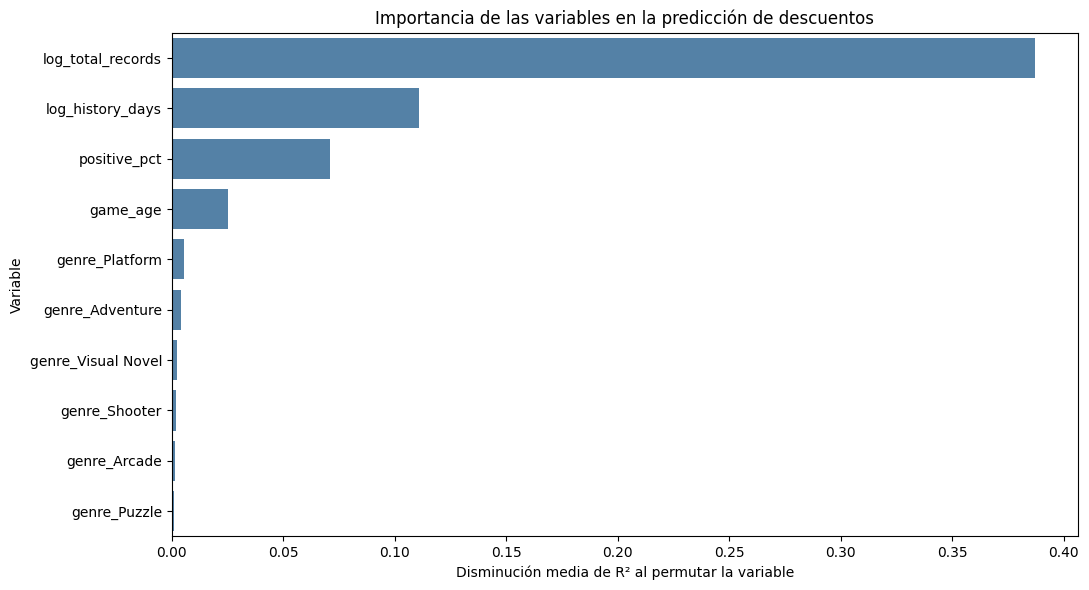

In [41]:
df_top_importance = df_itad_importance.head(10)

plt.figure(figsize=(11, 6))

sns.barplot(
    data=df_top_importance,
    x="importance_mean",
    y="feature",
    color="steelblue"
)

plt.title("Importancia de las variables en la predicción de descuentos")
plt.xlabel("Disminución media de R² al permutar la variable")
plt.ylabel("Variable")

plt.tight_layout()
plt.show()

Las valoraciones de los jugadores aportan información relevante para explicar los descuentos históricos de los videojuegos.

El análisis conjunto de IGDB, Steam e ITAD identifica una asociación negativa entre la satisfacción de los jugadores y el descuento máximo observado (Spearman ρ = −0,297; p < 0,001). Al incorporar el porcentaje de reseñas positivas a una regresión lineal que considera la antigüedad, la cobertura del historial de precios y las características de los videojuegos, el R² en test aumenta de 0,572 a 0,612 y el error absoluto medio disminuye un 5,54 %.

Los resultados sugieren que las valoraciones contienen información adicional sobre el comportamiento histórico de los descuentos, aunque no permiten establecer una relación causal.

¿Qué nos dicen los coeficientes de la regresión lineal?
Los coeficientes indican cómo cambia el descuento máximo estimado cuando aumenta una variable, manteniendo constantes las demás variables del modelo.
El resultado principal: positive_pct
Coeficiente de valoraciones positivas
−0,2970
Puntos porcentuales de descuento por cada punto adicional de valoración positiva

El coeficiente es negativo, tal y como sugería nuestra correlación inicial de Spearman.

Esto significa que, según nuestra regresión lineal, un videojuego con 10 puntos porcentuales más de valoraciones positivas presenta un descuento máximo estimado 2,97 puntos porcentuales inferior, manteniendo constantes las demás variables.

Por ejemplo:
Diferencia de valoración positiva	Diferencia estimada de descuento máximo
+5 puntos porcentuales	−1,49 puntos
+10 puntos porcentuales	−2,97 puntos
+20 puntos porcentuales	−5,94 puntos
+30 puntos porcentuales	−8,91 puntos

Son diferencias estimadas por el modelo, no descuentos reales de videojuegos concretos.

Esto es relevante porque la relación negativa persiste incluso después de incluir antigüedad, cobertura del historial, géneros e Indie.
Antigüedad y cobertura histórica
Variable	Coeficiente	Interpretación
game_age	+0,5152	Cada año adicional de antigüedad se asocia con 0,52 puntos más de descuento máximo
log_history_days	+4,1000	Una mayor duración del historial se asocia con descuentos máximos superiores
log_total_records	+9,4443	Un mayor número de observaciones se asocia con descuentos máximos superiores

Los dos últimos coeficientes corresponden a variables transformadas con log1p(). No podemos interpretarlos como un aumento fijo por cada día o cada registro adicional.

Para cambios suficientemente grandes, duplicar aproximadamente la duración del historial se asociaría con unos 2,84 puntos porcentuales más de descuento; duplicar aproximadamente el número de registros, con unos 6,55 puntos adicionales, manteniendo lo demás constante.

Es importante recordar que estas variables describen también nuestra cobertura de observación, no únicamente el comportamiento comercial del videojuego.
Géneros e Indie
Algunos coeficientes destacan:
- genre_Sport: +5,59.
- genre_Platform: +5,25.
- genre_Visual Novel: −3,14.
- genre_Role-playing (RPG): −2,64.
- is_indie: −0,62.
En el modelo, estas variables representan diferencias estimadas de descuento máximo en puntos porcentuales, condicionadas a las demás características.

Aquí entra Permutation Importance.

A diferencia de los coeficientes, esta técnica mide cuánto empeora el modelo cuando desordenamos una variable en el conjunto de test.

¿Podemos responder a nuestra pregunta principal?
¿Los videojuegos con mejores valoraciones reciben menos descuentos?

La respuesta que respaldan nuestros datos es:

Sí, encontramos una asociación negativa entre las valoraciones positivas de Steam y los descuentos máximos históricos observados. Esa asociación también aparece en una regresión lineal multivariable y las valoraciones mejoran el rendimiento predictivo fuera del entrenamiento.

Sin embargo, hay una limitación que merece quedar explícita en el informe: estamos utilizando el mayor descuento registrado durante un historial de duración variable y las valoraciones observadas en nuestra extracción de 2026.

Por tanto, no podemos afirmar que las buenas valoraciones provoquen descuentos menores, ni que un juego mejor valorado vaya a tener menos descuentos en el futuro. Tampoco hemos estimado la frecuencia real de las promociones, solo su intensidad máxima registrada.

Además, el número de registros y la duración del historial son variables conocidas a posteriori. Nuestro modelo es adecuado para estudiar asociaciones retrospectivas, pero no está validado como sistema para predecir descuentos de nuevos videojuegos.

5. Conclusión final para incorporar al informe
Relación entre la satisfacción de los jugadores y los descuentos históricos
El análisis conjunto de IGDB, Steam e IsThereAnyDeal muestra que los videojuegos con mejores valoraciones tienden a presentar descuentos máximos históricos inferiores en Steam.

La correlación de Spearman identifica una asociación negativa estadísticamente significativa entre el porcentaje de reseñas positivas y el descuento máximo observado (ρ = −0,297; p < 0,001). Los videojuegos con valoraciones muy positivas presentan una mediana de descuento máximo del 50 %, frente al 80 % de los videojuegos con valoraciones mixtas.

Para comprobar si esta relación se mantiene al considerar otros factores, se desarrollaron dos modelos de regresión lineal: uno basado en antigüedad, cobertura histórica, géneros y clasificación Indie, y otro que incorpora adicionalmente el porcentaje de valoraciones positivas.

El segundo modelo mejoró el R² en test de 0,572 a 0,612 y redujo el error absoluto medio un 5,54 %. El coeficiente asociado a las valoraciones fue negativo (−0,297), lo que equivale a una diferencia estimada de −2,97 puntos porcentuales de descuento máximo por cada 10 puntos adicionales de valoración positiva, manteniendo constantes las demás variables del modelo.

El análisis de importancia por permutación situó las valoraciones positivas como la tercera variable más relevante para las predicciones, por detrás del número de registros y de la duración del historial.

Estos resultados respaldan la existencia de una asociación entre la satisfacción de los jugadores y la intensidad máxima de los descuentos observados. No obstante, la elevada influencia de la cobertura histórica y la naturaleza retrospectiva de los datos impiden establecer relaciones causales o extrapolar directamente los resultados a futuras promociones.

#####################################################

# Random Forest